In [2]:
import copy
from pathlib import Path

import requests
from IPython.display import display
import numpy as np
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem
import mdtraj as md
import pdbfixer
import openmm as mm
import openmm.app as app
from openmm import unit
from openff.toolkit.topology import Molecule, Topology
from openmmforcefields.generators import GAFFTemplateGenerator

We go to the worldwide Protein Data Bank (PDB) website, download the raw, official 3D coordinate file for our target protein in complex with its drug molecule (PDB ID: 3POZ), and save it locally on your computer:

In [3]:

pdbid = "3POZ"
ligand_name = "03P"
pdb_path = f"{pdbid}.pdb"
pdb_url = f"https://files.rcsb.org/download/{pdbid}.pdb"

In [4]:
r = requests.get(pdb_url)
r.raise_for_status()
with open(pdb_path, "wb") as f:
    f.write(r.content)

Real experimental crystal structures from the lab are messy. They are missing tiny hydrogen atoms, sometimes have broken loops, or contain weird non-standard amino acid codes. This function uses pdbfixer to strip out any random extra molecules, fill in missing backbone pieces, and snap all the missing hydrogen atoms back onto the protein at a neutral pH (7.0):

In [5]:
def prepare_protein(
    pdb_file, ignore_missing_residues=True, ignore_terminal_missing_residues=True, ph=7.0
):
    """
    Use pdbfixer to prepare the protein from a PDB file. Hetero atoms such as ligands are
    removed and non-standard residues replaced. Missing atoms to existing residues are added.
    Missing residues are ignored by default, but can be included.

    Parameters
    ----------
    pdb_file: pathlib.Path or str
        PDB file containing the system to simulate.
    ignore_missing_residues: bool, optional
        If missing residues should be ignored or built.
    ignore_terminal_missing_residues: bool, optional
        If missing residues at the beginning and the end of a chain should be ignored or built.
    ph: float, optional
        pH value used to determine protonation state of residues

    Returns
    -------
    fixer: pdbfixer.pdbfixer.PDBFixer
        Prepared protein system.
    """
    fixer = pdbfixer.PDBFixer(str(pdb_file))
    fixer.removeHeterogens()  # co-crystallized ligands are unknown to PDBFixer
    fixer.findMissingResidues()  # identify missing residues, needed for identification of missing atoms

    # if missing terminal residues shall be ignored, remove them from the dictionary
    if ignore_terminal_missing_residues:
        chains = list(fixer.topology.chains())
        keys = fixer.missingResidues.keys()
        for key in list(keys):
            chain = chains[key[0]]
            if key[1] == 0 or key[1] == len(list(chain.residues())):
                del fixer.missingResidues[key]

    # if all missing residues shall be ignored ignored, clear the dictionary
    if ignore_missing_residues:
        fixer.missingResidues = {}

    fixer.findNonstandardResidues()  # find non-standard residue
    fixer.replaceNonstandardResidues()  # replace non-standard residues with standard one
    fixer.findMissingAtoms()  # find missing heavy atoms
    fixer.addMissingAtoms()  # add missing atoms and residues
    fixer.addMissingHydrogens(ph)  # add missing hydrogens
    return fixer

In [6]:
# prepare protein and build only missing non-terminal residues
prepared_protein = prepare_protein(pdb_path, ignore_missing_residues=False)

The crystal structure photo doesn't show chemical bond types (single, double, aromatic) for the drug, and its hydrogens are missing. We slice just the drug (03P) out of the PDB file, and then use a clean chemical text blueprint (the SMILES string) as a template to force the correct bond orders and protonation states onto its 3D coordinates:

In [7]:
def prepare_ligand(pdb_file, resname, smiles, depict=True):
    """
    Prepare a ligand from a PDB file via adding hydrogens and assigning bond orders. A depiction
    of the ligand before and after preparation is rendered in 2D to allow an inspection of the
    results. Huge thanks to @j-wags for the suggestion.

    Parameters
    ----------
    pdb_file: pathlib.PosixPath
       PDB file containing the ligand of interest.
    resname: str
        Three character residue name of the ligand.
    smiles : str
        SMILES string of the ligand informing about correct protonation and bond orders.
    depict: bool, optional
        show a 2D representation of the ligand

    Returns
    -------
    prepared_ligand: rdkit.Chem.rdchem.Mol
        Prepared ligand.
    """
    # split molecule
    rdkit_mol = Chem.MolFromPDBFile(str(pdb_file))
    rdkit_mol_split = Chem.rdmolops.SplitMolByPDBResidues(rdkit_mol)

    # extract the ligand and remove any already present hydrogens
    ligand = rdkit_mol_split[resname]
    ligand = Chem.RemoveHs(ligand)

    # assign bond orders from template
    reference_mol = Chem.MolFromSmiles(smiles)
    prepared_ligand = AllChem.AssignBondOrdersFromTemplate(reference_mol, ligand)
    prepared_ligand.AddConformer(ligand.GetConformer(0))

    # protonate ligand
    prepared_ligand = Chem.rdmolops.AddHs(prepared_ligand, addCoords=True)
    prepared_ligand = Chem.MolFromMolBlock(Chem.MolToMolBlock(prepared_ligand))

    # 2D depiction
    if depict:
        ligand_2d = copy.deepcopy(ligand)
        prepared_ligand_2d = copy.deepcopy(prepared_ligand)
        AllChem.Compute2DCoords(ligand_2d)
        AllChem.Compute2DCoords(prepared_ligand_2d)
        display(
            Draw.MolsToGridImage(
                [ligand_2d, prepared_ligand_2d], molsPerRow=2, legends=["original", "prepared"]
            )
        )

    # return ligand
    return prepared_ligand

[16:54:44] WARNING: More than one matching pattern found - picking one



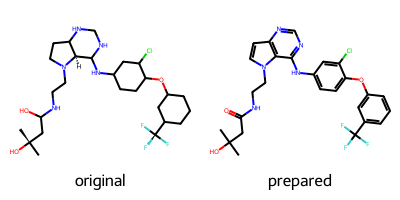

In [8]:
smiles = "CC(C)(O)CC(=O)NCCn1ccc2ncnc(Nc3ccc(Oc4cccc(c4)C(F)(F)F)c(Cl)c3)c12"
rdkit_ligand = prepare_ligand(pdb_path, ligand_name, smiles)

Translate the Drug into OpenMM Language (OpenFF):

In [9]:
def rdkit_to_openmm(rdkit_mol, name="LIG"):
    """
    Convert an RDKit molecule to an OpenMM molecule.
    Inspired by @hannahbrucemcdonald and @glass-w.

    Parameters
    ----------
    rdkit_mol: rdkit.Chem.rdchem.Mol
        RDKit molecule to convert.
    name: str
        Molecule name.

    Returns
    -------
    omm_molecule: openmm.app.Modeller
        OpenMM modeller object holding the molecule of interest.
    """
    # convert RDKit to OpenFF
    off_mol = Molecule.from_rdkit(rdkit_mol)

    # add name for molecule
    off_mol.name = name

    # add names for atoms
    element_counter_dict = {}
    for off_atom, rdkit_atom in zip(off_mol.atoms, rdkit_mol.GetAtoms()):
        element = rdkit_atom.GetSymbol()
        if element in element_counter_dict.keys():
            element_counter_dict[element] += 1
        else:
            element_counter_dict[element] = 1
        off_atom.name = element + str(element_counter_dict[element])

    # convert from OpenFF to OpenMM
    off_mol_topology = off_mol.to_topology()
    mol_topology = off_mol_topology.to_openmm()
    mol_positions = off_mol.conformers[0]

    # convert units from Ångström to nanometers
    # since OpenMM works in nm
    mol_positions = mol_positions.to("nanometers")

    # combine topology and positions in modeller object
    omm_mol = app.Modeller(mol_topology, mol_positions)

    return omm_mol

In [10]:
omm_ligand = rdkit_to_openmm(rdkit_ligand, ligand_name)

Now we have a cleaned-up protein and a prepared drug sitting in separate digital containers. We use MDTraj to snap their topologies and 3D coordinate matrices together into a single, unified protein-ligand complex system ready for simulation:

In [11]:
def merge_protein_and_ligand(protein, ligand):
    """
    Merge two OpenMM objects.

    Parameters
    ----------
    protein: pdbfixer.pdbfixer.PDBFixer
        Protein to merge.
    ligand: openmm.app.Modeller
        Ligand to merge.

    Returns
    -------
    complex_topology: openmm.app.topology.Topology
        The merged topology.
    complex_positions: openmm.unit.quantity.Quantity
        The merged positions.
    """
    # combine topologies
    md_protein_topology = md.Topology.from_openmm(protein.topology)  # using mdtraj for protein top
    md_ligand_topology = md.Topology.from_openmm(ligand.topology)  # using mdtraj for ligand top
    md_complex_topology = md_protein_topology.join(md_ligand_topology)  # add them together
    complex_topology = md_complex_topology.to_openmm()

    # combine positions
    total_atoms = len(protein.positions) + len(ligand.positions)

    # create an array for storing all atom positions as tupels containing a value and a unit
    # called OpenMM Quantities
    complex_positions = unit.Quantity(np.zeros([total_atoms, 3]), unit=unit.nanometers)
    complex_positions[: len(protein.positions)] = protein.positions  # add protein positions
    complex_positions[len(protein.positions) :] = ligand.positions  # add ligand positions

    return complex_topology, complex_positions

In [12]:
complex_topology, complex_positions = merge_protein_and_ligand(prepared_protein, omm_ligand)

/opt/anaconda3/envs/stable_opencadd/lib/python3.10/site-packages/openmm/unit/quantity.py:749: UnitStrippedWarning: The unit of the quantity is stripped when downcasting to ndarray.
  self._value[key] = value / self.unit


In [13]:
print("Complex topology has", complex_topology.getNumAtoms(), "atoms.")
# NBVAL_CHECK_OUTPUT

Complex topology has 5561 atoms.


In [14]:
def generate_forcefield(
    rdkit_mol=None, protein_ff="amber14-all.xml", solvent_ff="amber14/tip3pfb.xml"
):
    """
    Generate an OpenMM Forcefield object and register a small molecule.

    Parameters
    ----------
    rdkit_mol: rdkit.Chem.rdchem.Mol
        Small molecule to register in the force field.
    protein_ff: string
        Name of the force field.
    solvent_ff: string
        Name of the solvent force field.

    Returns
    -------
    forcefield: openmm.app.Forcefield
        Forcefield with registered small molecule.
    """
    forcefield = app.ForceField(protein_ff, solvent_ff)

    if rdkit_mol is not None:
        gaff = GAFFTemplateGenerator(
            forcefield="gaff-2.1",
            molecules=Molecule.from_rdkit(rdkit_mol, allow_undefined_stereo=True),
        )
        forcefield.registerTemplateGenerator(gaff.generator)

    return forcefield

In [15]:
forcefield = generate_forcefield(rdkit_ligand)

In [16]:
modeller = app.Modeller(complex_topology, complex_positions)
modeller.addSolvent(forcefield, padding=1.0 * unit.nanometers, ionicStrength=0.15 * unit.molar)

In [133]:
system = forcefield.createSystem(modeller.topology, nonbondedMethod=app.PME)
integrator = mm.LangevinIntegrator(
    300 * unit.kelvin, 1.0 / unit.picoseconds, 2.0 * unit.femtoseconds
)
simulation = app.Simulation(modeller.topology, system, integrator)
simulation.context.setPositions(modeller.positions)

In [134]:
simulation.minimizeEnergy()
with open("topology.pdb", "w") as pdb_file:
    app.PDBFile.writeFile(
        simulation.topology,
        simulation.context.getState(getPositions=True, enforcePeriodicBox=True).getPositions(),
        file=pdb_file,
        keepIds=True,
    )

steps = 50000          
write_interval = 500   
log_interval = 2500

The notebook takes 2 femtoseconds per step. That’s the tiny time unit.

To get 100 picoseconds, we convert the units:
- 1 picosecond = 1,000 femtoseconds
- 100 picoseconds = 100,000 femtoseconds
- 100,000 femtoseconds ÷ 2 femtoseconds per step = 50,000 steps

In [135]:
import sys

# 1. Choose how many steps to run 
# (Set short test steps locally so your laptop doesn't freeze, or crank it up if you're on Colab/GPU)
on_colab = False  # Change to True if running on Google Colab with a GPU

if on_colab:
    steps = 50000        # 100 picoseconds of simulation time
    write_interval = 500 # save a frame every 1 ps
    log_interval = 2500  
else:
    steps = 50000           # A tiny 20-femtosecond test run for local debugging
    write_interval = 500
    log_interval = 2500

# 2. Attach OpenMM's native XTC reporter to record the 3D trajectory frames
simulation.reporters.append(
    app.XTCReporter(str("trajectory_ns5.xtc"), reportInterval=write_interval)
)

# 3. Attach OpenMM's StateDataReporter to print live stats (energy, temp, speed) to your screen
simulation.reporters.append(
    app.StateDataReporter(
        sys.stdout,
        log_interval,
        step=True,
        potentialEnergy=True,
        temperature=True,
        progress=True,
        remainingTime=True,
        speed=True,
        totalSteps=steps,
        separator="\t",
    )
)

# 4. Run the actual simulation steps!
print(f"Running simulation for {steps} steps...")
simulation.step(steps)
print("Simulation complete! Trajectory saved.")

Running simulation for 50000 steps...
#"Progress (%)"	"Step"	"Potential Energy (kJ/mole)"	"Temperature (K)"	"Speed (ns/day)"	"Time Remaining"
5.0%	2500	-887786.6378575326	296.8535250701299	0	--
10.0%	5000	-883564.4503575326	298.90487682099433	32.8	3:56
15.0%	7500	-883420.5128575326	298.6410704974611	32.8	3:43
20.0%	10000	-883778.2941075326	300.8141191963962	32.8	3:30
25.0%	12500	-883124.7628575326	301.02692685212776	32.8	3:17
30.0%	15000	-884330.3878575326	302.65447772951956	32.8	3:04
35.0%	17500	-885088.2628575326	300.46509908867074	32.8	2:51
40.0%	20000	-883468.8878575326	300.6109669428278	32.8	2:38
45.0%	22500	-883998.2628575326	301.3122472261187	32.8	2:24
50.0%	25000	-885058.6691075326	300.1203558704941	32.8	2:11
55.0%	27500	-883340.7628575326	300.4978237738548	32.8	1:58
60.0%	30000	-884295.8878575326	299.28931087021107	32.8	1:45
65.0%	32500	-885785.7628575326	300.19588185184466	32.8	1:32
70.0%	35000	-883828.6066075326	298.8559517966102	32.8	1:18
75.0%	37500	-884512.2316075326	300.

T020: Analysis

In [136]:
import mdtraj as md

traj = md.load("trajectory_ns5.xtc", top="topology.pdb")
print(traj)

<mdtraj.Trajectory with 100 frames, 55362 atoms, 17109 residues, and unitcells>


In [137]:
import nglview as nv
view = nv.show_mdtraj(traj)
view

NGLWidget(max_frame=99)

In [138]:
from collections import Counter

print(Counter(res.name for res in top.residues))

Counter({'HOH': 16694, 'NA': 52, 'CL': 45, 'LEU': 33, 'GLU': 25, 'ILE': 24, 'LYS': 23, 'VAL': 23, 'ASP': 21, 'ALA': 19, 'GLY': 18, 'ARG': 16, 'SER': 16, 'PRO': 16, 'THR': 13, 'TYR': 13, 'MET': 12, 'GLN': 10, 'PHE': 8, 'HIS': 8, 'ASN': 7, 'TRP': 6, 'CYS': 6, 'UNK': 1})


In [139]:
ligand = np.array([
    atom.index for atom in top.atoms
    if atom.residue.name == "UNK"
], dtype=int)

print("Ligand atoms:", len(ligand))

Ligand atoms: 63


In [140]:
import numpy as np
import pandas as pd

top = traj.topology
protein = top.select("protein")
backbone = top.select("protein and backbone")
ligand = np.array([
    atom.index for atom in top.atoms
    if atom.residue.name == "UNK"
], dtype=int)

# Align every frame to frame 0 using the protein backbone
traj.superpose(traj, 0, atom_indices=backbone)

# RMSD from frame 0 after that backbone alignment; MDTraj coordinates are nm
def rmsd_after_alignment(atom_indices):
    xyz = traj.xyz[:, atom_indices, :]
    delta = xyz - xyz[0]
    return np.sqrt(np.mean(np.sum(delta**2, axis=2), axis=1)) * 10  # Å

rmsd = pd.DataFrame({
    "backbone (Å)": rmsd_after_alignment(backbone),
    "protein (Å)": rmsd_after_alignment(protein),
    "ligand (Å)": rmsd_after_alignment(ligand),
})
rmsd.index.name = "frame"
rmsd

,backbone (Å),protein (Å),ligand (Å)
frame,,,
0,0.000000,0.000000,0.000000
1,0.649739,0.820374,0.710878
2,0.730518,0.903332,0.697464
3,0.758260,0.973315,0.720954
4,0.800207,1.046044,0.701018
...,...,...,...
95,1.451046,1.850868,1.047145
96,1.349477,1.775777,0.582960
97,1.336908,1.793464,1.035783


Text(0, 0.5, 'RMSD (Å)')

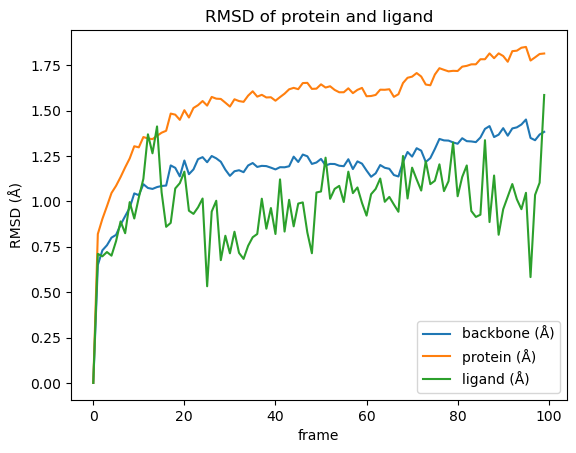

In [142]:
ax = rmsd.plot(title="RMSD of protein and ligand")
ax.set_ylabel("RMSD (Å)")

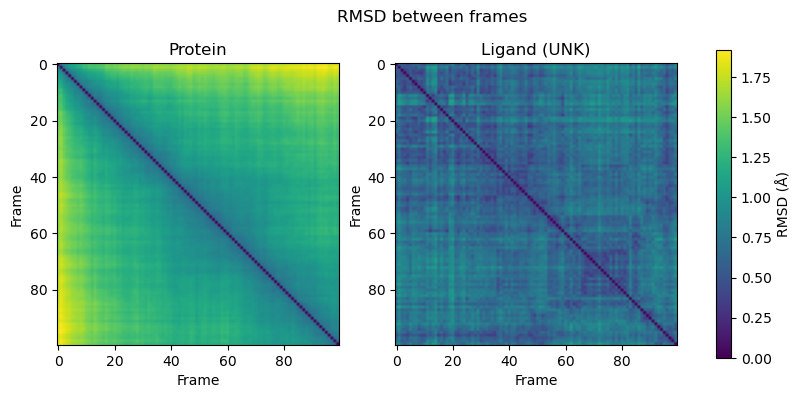

In [143]:
import matplotlib.pyplot as plt
import numpy as np
import mdtraj as md

n_frames = traj.n_frames
protein_rmsd = np.zeros((n_frames, n_frames))
ligand_rmsd = np.zeros((n_frames, n_frames))

# Each call compares every frame to one reference frame.
# MDTraj returns nm; multiply by 10 for Å.
for j in range(n_frames):
    protein_rmsd[:, j] = md.rmsd(
        traj, traj, frame=j, atom_indices=protein
    ) * 10
    ligand_rmsd[:, j] = md.rmsd(
        traj, traj, frame=j, atom_indices=ligand
    ) * 10

# Use the same color scale for both heatmaps
max_rmsd = max(protein_rmsd.max(), ligand_rmsd.max())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

im = ax[0].imshow(protein_rmsd, cmap="viridis", vmin=0, vmax=max_rmsd)
ax[0].set_title("Protein")
ax[0].set_xlabel("Frame")
ax[0].set_ylabel("Frame")

ax[1].imshow(ligand_rmsd, cmap="viridis", vmin=0, vmax=max_rmsd)
ax[1].set_title("Ligand (UNK)")
ax[1].set_xlabel("Frame")
ax[1].set_ylabel("Frame")

fig.colorbar(im, ax=ax, label="RMSD (Å)")
fig.suptitle("RMSD between frames")
plt.show()

In [144]:
# Find ligand atoms and protein atoms
ligand_atoms = top.select("resname UNK")
protein_atoms = top.select("protein")

# Find protein atoms within 5 Å of the ligand in frame 0
nearby_atoms = md.compute_neighbors(
    traj[0],
    cutoff=0.5,
    query_indices=ligand_atoms,
    haystack_indices=protein_atoms,
    periodic=False,
)[0]

# Expand nearby atoms to their full protein residues
pocket_residue_ids = {
    top.atom(i).residue.index for i in nearby_atoms
}
pocket_atoms = np.array([
    atom.index for atom in top.atoms
    if atom.residue.index in pocket_residue_ids
], dtype=int)

# Display those residues plus the ligand
display_atoms = np.unique(np.concatenate([pocket_atoms, ligand_atoms]))
pocket_traj = traj[0].atom_slice(display_atoms)

view2 = nv.show_mdtraj(pocket_traj)
view2.clear_representations()
view2.add_representation("cartoon", selection="protein")
view2.add_representation("licorice")
view2.center()
view2

NGLWidget()

In [145]:
for atom in top.atoms:
    if atom.residue.name == "UNK":
        print("LIGAND", atom.index, atom.residue.name, atom.name, atom.element.symbol)
    elif atom.residue.is_protein:
        print("PROTEIN", atom.index, atom.residue.name, atom.name, atom.element.symbol)

PROTEIN 0 GLN N N
PROTEIN 1 GLN H H
PROTEIN 2 GLN H2 H
PROTEIN 3 GLN H3 H
PROTEIN 4 GLN CA C
PROTEIN 5 GLN HA H
PROTEIN 6 GLN C C
PROTEIN 7 GLN O O
PROTEIN 8 GLN CB C
PROTEIN 9 GLN HB2 H
PROTEIN 10 GLN HB3 H
PROTEIN 11 GLN CG C
PROTEIN 12 GLN HG2 H
PROTEIN 13 GLN HG3 H
PROTEIN 14 GLN CD C
PROTEIN 15 GLN OE1 O
PROTEIN 16 GLN NE2 N
PROTEIN 17 GLN HE21 H
PROTEIN 18 GLN HE22 H
PROTEIN 19 ALA N N
PROTEIN 20 ALA H H
PROTEIN 21 ALA CA C
PROTEIN 22 ALA HA H
PROTEIN 23 ALA C C
PROTEIN 24 ALA O O
PROTEIN 25 ALA CB C
PROTEIN 26 ALA HB1 H
PROTEIN 27 ALA HB2 H
PROTEIN 28 ALA HB3 H
PROTEIN 29 LEU N N
PROTEIN 30 LEU H H
PROTEIN 31 LEU CA C
PROTEIN 32 LEU HA H
PROTEIN 33 LEU C C
PROTEIN 34 LEU O O
PROTEIN 35 LEU CB C
PROTEIN 36 LEU HB2 H
PROTEIN 37 LEU HB3 H
PROTEIN 38 LEU CG C
PROTEIN 39 LEU HG H
PROTEIN 40 LEU CD1 C
PROTEIN 41 LEU HD11 H
PROTEIN 42 LEU HD12 H
PROTEIN 43 LEU HD13 H
PROTEIN 44 LEU CD2 C
PROTEIN 45 LEU HD21 H
PROTEIN 46 LEU HD22 H
PROTEIN 47 LEU HD23 H
PROTEIN 48 LEU N N
PROTEIN 49 LEU

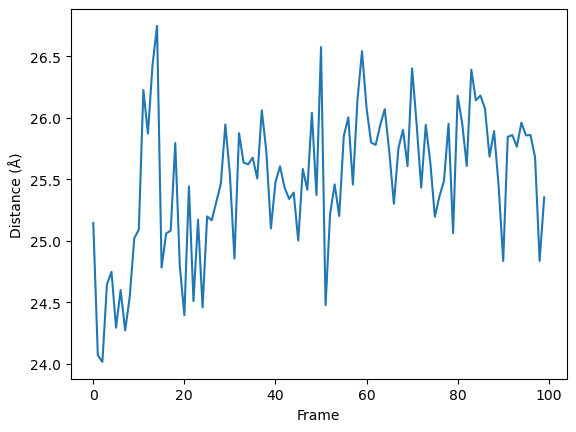

In [146]:
protein_idx = 24
ligand_idx = 5557  # example only—confirm this index is a ligand atom

distances_A = md.compute_distances(
    traj,
    np.array([[protein_idx, ligand_idx]], dtype=int),
    periodic=False
)[:, 0] * 10

plt.plot(distances_A)
plt.xlabel("Frame")
plt.ylabel("Distance (Å)")
plt.show()

In [147]:
hbonds = md.baker_hubbard(traj, freq=0.1, exclude_water=True)

In [148]:
for donor_idx, hydrogen_idx, acceptor_idx in hbonds:
    donor = top.atom(donor_idx)
    hydrogen = top.atom(hydrogen_idx)
    acceptor = top.atom(acceptor_idx)

    if donor.residue.name == "UNK" or acceptor.residue.name == "UNK":
        print(f"{donor} – {hydrogen} ··· {acceptor}")

MET793-N – MET793-H ··· UNK0-N4x
UNK0-N3x – UNK0-H18x ··· UNK0-O2x
UNK0-O3x – UNK0-H22x ··· ASN842-OD1


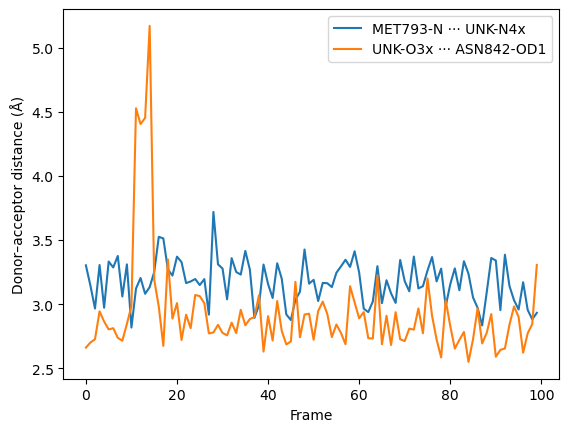

In [149]:
# Look up atoms by residue name/number and atom name
def atom_index(resname, resseq, atom_name):
    matches = [
        atom.index for atom in top.atoms
        if atom.residue.name == resname
        and atom.residue.resSeq == resseq
        and atom.name == atom_name
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one match, found {len(matches)}: "
                         f"{resname}{resseq}-{atom_name}")
    return matches[0]

# MET793-N ··· UNK0-N4x
pair1 = (
    atom_index("MET", 793, "N"),
    atom_index("UNK", 0, "N4x")
)

# UNK0-O3x ··· ASN842-OD1
pair2 = (
    atom_index("UNK", 0, "O3x"),
    atom_index("ASN", 842, "OD1")
)

pairs = np.array([pair1, pair2], dtype=int)
distances_A = md.compute_distances(traj, pairs, periodic=False) * 10

import matplotlib.pyplot as plt

plt.plot(distances_A[:, 0], label="MET793-N ··· UNK-N4x")
plt.plot(distances_A[:, 1], label="UNK-O3x ··· ASN842-OD1")
plt.xlabel("Frame")
plt.ylabel("Donor–acceptor distance (Å)")
plt.legend()
plt.show()